# Pakistan Census 2017: Population Analysis (1998 to 2017)

*Graph interpretations and key findings from the tehsil-level population dataset*

**Tools:** Python, pandas, NumPy, matplotlib, seaborn

## 1. About the Dataset

- The file (`Population-Dataset.csv`) has 528 rows and 21 columns. Each row is one tehsil (a sub-division of a district). Together the rows cover 131 districts in Punjab, Sindh, KPK, Balochistan and the former tribal areas, which the census lists separately as KPK/FATA.
- Every population figure is given twice, once for the rural part and once for the urban part of the tehsil. This includes total people, males, females, transgender persons, sex ratio, average household size, the 1998 population and the yearly growth rate.
- No cell is empty, so the file looks clean at first glance. The real problems only show up when the numbers are checked more carefully (Section 2).
- Tehsils differ a great deal in size. The smallest one, Sangan Sub-Tehsil, has only 2,665 people, while Peshawar Tehsil has 4.27 million, which is more than 1,600 times as many.
- Islamabad is not part of this file, so the national total used in this report is a little lower than the official census figure.

### Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# One simple, consistent style for all charts
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 13, "axes.titleweight": "bold", "grid.color": "#e6e6e3"})

# Show big numbers as 1.2M / 450K instead of 1e8
def human(x, _=None):
    if abs(x) >= 1e6: return f"{x/1e6:.1f}M"
    if abs(x) >= 1e3: return f"{x/1e3:.0f}K"
    return f"{x:.0f}"
HUMAN = mtick.FuncFormatter(human)

### Load the data

In [2]:
df = pd.read_csv("Population-Dataset.csv")
df.columns = df.columns.str.strip().str.upper()
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (528, 21)


,PROVINCE,DIVISION,DISTRICT,SUB DIVISION,AREA (SQ.KM),ALL SEXES (RURAL),MALE (RURAL),FEMALE (RURAL),TRANSGENDER (RURAL),SEX RATIO (RURAL),...,POPULATION 1998 (RURAL),ANNUAL GROWTH RATE (RURAL),ALL SEXES (URBAN),MALE (URBAN),FEMALE (URBAN),TRANSGENDER (URBAN),SEX RATIO (URBAN),AVG HOUSEHOLD SIZE (URBAN),POPULATION 1998 (URBAN),ANNUAL GROWTH RATE (URBAN)
0,PUNJAB,BAHAWALPUR DIVISION,BAHAWALNAGAR DISTRICT,BAHAWALNAGAR TEHSIL,1729.0,619550,316864,302644,42,104.70,...,407768,2.22,193840,98391,95402,47,103.13,6.02,133785,1.97
1,PUNJAB,BAHAWALPUR DIVISION,BAHAWALNAGAR DISTRICT,CHISHTIAN TEHSIL,1500.0,540342,273788,266500,54,102.73,...,395983,1.65,149424,75546,73851,27,102.30,6.01,102287,2.01
2,PUNJAB,BAHAWALPUR DIVISION,BAHAWALNAGAR DISTRICT,FORT ABBAS TEHSIL,2536.0,361240,182655,178541,44,102.30,...,250959,1.93,61528,31360,30150,18,104.01,6.00,34637,3.06
3,PUNJAB,BAHAWALPUR DIVISION,BAHAWALNAGAR DISTRICT,HAROONABAD TEHSIL,1295.0,382115,192278,189808,29,101.30,...,297343,1.33,142600,71345,71236,19,100.15,6.02,84424,2.79
4,PUNJAB,BAHAWALPUR DIVISION,BAHAWALNAGAR DISTRICT,MINCHINABAD TEHSIL,1818.0,452723,231506,221178,39,104.67,...,316593,1.90,72294,36694,35590,10,103.10,6.34,37668,3.48


In [3]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
AREA (SQ.KM),528.0,1492.0,2039.5,0.0,425.0,882.0,1734.2,18374.0
ALL SEXES (RURAL),528.0,246278.0,271189.8,0.0,50934.5,165241.0,312911.2,2297375.0
MALE (RURAL),528.0,125275.7,137563.0,0.0,27127.2,84134.5,160502.2,1172995.0
FEMALE (RURAL),528.0,120984.1,133716.9,0.0,23979.0,82044.0,152219.0,1124167.0
TRANSGENDER (RURAL),528.0,18.2,25.5,0.0,1.0,10.0,25.0,213.0
SEX RATIO (RURAL),528.0,99.0,26.8,0.0,101.1,105.3,108.3,139.4
AVG HOUSEHOLD SIZE (RURAL),528.0,6.3,2.1,0.0,5.7,6.3,7.2,12.4
POPULATION 1998 (RURAL),528.0,167428.0,178389.0,0.0,35273.5,117206.5,213054.2,1044035.0
ANNUAL GROWTH RATE (RURAL),528.0,3.1,9.6,0.0,1.4,2.0,2.8,100.0
ALL SEXES (URBAN),528.0,140863.5,351246.3,0.0,0.0,43254.5,117814.8,3653616.0


## 2. Data Problems Found and How They Were Handled

- Four tehsils of Killa Saifullah (Badini, Kan Mehtarzai, Loiband and Muslim Bagh) show an area of 0 sq. km, which cannot be true. Dividing by zero would give them infinite density and put them at the top of every density ranking. Their area was therefore treated as unknown.
- In 155 tehsils nobody lives in the urban part, yet the urban sex ratio and urban household size are stored as 0. A normal average would treat these zeros as real values and give impossible results, for example an urban sex ratio of 15.6 for FATA. The zeros were replaced with blanks.
- Division names were typed in two styles (LAHORE DIVISION and Karachi Division, for example). Everything was converted to capital letters so that grouping works properly.
- FATA was merged into KPK in 2018, but the census still lists it separately. The original grouping is kept for the 1998 to 2017 comparison, and an extra column (`PROVINCE_2018`) was added for anyone who wants the present-day provincial map.
- Sex ratio in this file means males per 100 females, not females per 1,000 males. The first row confirms it: 316,864 males divided by 302,644 females, multiplied by 100, gives 104.7.
- One rule was followed everywhere: rates and ratios are never averaged across tehsils. A tehsil of 20,000 people would count as much as one of 2 million. Instead, the people are added up first and the ratio is worked out afterwards.

In [4]:
print("Missing values:", df.isna().sum().sum())
print("\nSub-divisions with AREA = 0:")
print(df.loc[df["AREA (SQ.KM)"] == 0, ["DISTRICT", "SUB DIVISION", "AREA (SQ.KM)"]].to_string())

no_urban = df["ALL SEXES (URBAN)"] == 0
print("\nSub-divisions with NO urban population:", no_urban.sum())
print("  ...but their URBAN sex ratio is stored as:", df.loc[no_urban, "SEX RATIO (URBAN)"].unique())
print("  ...and URBAN household size is stored as:", df.loc[no_urban, "AVG HOUSEHOLD SIZE (URBAN)"].unique())

print("\nDivision names in mixed case:", df.loc[df["DIVISION"].str.contains("[a-z]"), "DIVISION"].unique()[:5], "...")
print("\nProvinces:", df["PROVINCE"].unique())

Missing values: 0

Sub-divisions with AREA = 0:
                     DISTRICT              SUB DIVISION  AREA (SQ.KM)
393  KILLA SAIFULLAH DISTRICT         BADINI SUB-TEHSIL           0.0
394  KILLA SAIFULLAH DISTRICT  KAN MEHTARZAI SUB-TEHSIL           0.0
396  KILLA SAIFULLAH DISTRICT            LOIBAND TEHSIL           0.0
397  KILLA SAIFULLAH DISTRICT        MUSLIM BAGH TEHSIL           0.0

Sub-divisions with NO urban population: 155
  ...but their URBAN sex ratio is stored as: [0.]
  ...and URBAN household size is stored as: [0.]

Division names in mixed case: <StringArray>
[     'Badin Division',  'Hyderabad Division',    'Karachi Division',
    'Larkana Division', 'Mirpurkhas Division']
Length: 5, dtype: str ...

Provinces: <StringArray>
['PUNJAB', 'SINDH', 'BALOCHISTAN', 'KPK', 'KPK/FATA']
Length: 5, dtype: str


In [5]:
# 1) Area = 0 is impossible -> treat as unknown
df.loc[df["AREA (SQ.KM)"] == 0, "AREA (SQ.KM)"] = np.nan

# 2) Sex ratio / household size = 0 where there is no urban population -> unknown (not zero!)
for col in ["SEX RATIO (URBAN)", "AVG HOUSEHOLD SIZE (URBAN)"]:
    df.loc[df["ALL SEXES (URBAN)"] == 0, col] = np.nan

# 3) Same text style for names
df["DIVISION"] = df["DIVISION"].str.upper().str.strip()

# 4) FATA merged into KPK in 2018 -> keep a column for today's map too
df["PROVINCE_2018"] = df["PROVINCE"].replace({"KPK/FATA": "KPK"})

# 5) New columns
df["POP_2017"] = df["ALL SEXES (RURAL)"] + df["ALL SEXES (URBAN)"]
df["POP_1998"] = df["POPULATION 1998 (RURAL)"] + df["POPULATION 1998 (URBAN)"]
df["URBAN_2017"] = df["ALL SEXES (URBAN)"]
df["URBAN_1998"] = df["POPULATION 1998 (URBAN)"]
df["MALE"] = df["MALE (RURAL)"] + df["MALE (URBAN)"]
df["FEMALE"] = df["FEMALE (RURAL)"] + df["FEMALE (URBAN)"]
df["TRANSGENDER"] = df["TRANSGENDER (RURAL)"] + df["TRANSGENDER (URBAN)"]
# households = people / avg household size (needed to average household size correctly)
df["HH_RURAL"] = df["ALL SEXES (RURAL)"] / df["AVG HOUSEHOLD SIZE (RURAL)"]
df["HH_URBAN"] = (df["ALL SEXES (URBAN)"] / df["AVG HOUSEHOLD SIZE (URBAN)"]).fillna(0)

# Helper: yearly compound growth rate (CAGR) over 19 years
def cagr(new, old, years=19):
    return ((new / old) ** (1 / years) - 1) * 100
print("Clean ✔  |  Total population 2017:", f"{df.POP_2017.sum():,}")

Clean ✔  |  Total population 2017: 204,410,733


## 3. Headline Numbers

- Population grew from 130.7 million in 1998 to 204.4 million in 2017. That is 73.7 million extra people, a rise of 56% (Islamabad not included).
- Compounded over 19 years, this works out to 2.38% growth a year. At that speed the population would double in about 30 years.
- The urban share moved from 32.4% to 36.4%. City population rose from 42.3 million to 74.4 million, while village population rose from 88.4 million to 130.0 million. About two out of every three people still live in rural areas.
- There are 104.8 men for every 100 women.
- The census counted 21,358 transgender persons. 2017 was the first census to include this group.

In [6]:
P17, P98 = df.POP_2017.sum(), df.POP_1998.sum()
kpi = pd.Series({
    "Population 1998": f"{P98/1e6:.1f} M",
    "Population 2017": f"{P17/1e6:.1f} M",
    "People added": f"{(P17-P98)/1e6:.1f} M (+{(P17/P98-1):.0%})",
    "Yearly growth (CAGR)": f"{cagr(P17, P98):.2f}% per year",
    "Urban share 1998 → 2017": f"{df.URBAN_1998.sum()/P98:.1%} → {df.URBAN_2017.sum()/P17:.1%}",
    "Sex ratio (males per 100 females)": f"{df.MALE.sum()/df.FEMALE.sum()*100:.1f}",
    "Transgender persons counted": f"{df.TRANSGENDER.sum():,}",
    "Districts / Tehsils": f"{df.DISTRICT.nunique()} / {len(df)}",
})
print(kpi.to_string())

Population 1998                             130.7 M
Population 2017                             204.4 M
People added                          73.7 M (+56%)
Yearly growth (CAGR)                 2.38% per year
Urban share 1998 → 2017               32.4% → 36.4%
Sex ratio (males per 100 females)             104.8
Transgender persons counted                  21,358
Districts / Tehsils                       131 / 528


In [7]:
prov = df.groupby("PROVINCE").agg(POP_2017=("POP_2017", "sum"), POP_1998=("POP_1998", "sum"),
                                  URBAN_2017=("URBAN_2017", "sum"), URBAN_1998=("URBAN_1998", "sum"),
                                  RURAL_2017=("ALL SEXES (RURAL)", "sum"), RURAL_1998=("POPULATION 1998 (RURAL)", "sum"),
                                  AREA=("AREA (SQ.KM)", "sum"), MALE=("MALE", "sum"), FEMALE=("FEMALE", "sum"))
prov["SHARE"] = prov.POP_2017 / prov.POP_2017.sum()
prov["CAGR"] = cagr(prov.POP_2017, prov.POP_1998)
prov["URBAN_%_1998"] = prov.URBAN_1998 / prov.POP_1998 * 100
prov["URBAN_%_2017"] = prov.URBAN_2017 / prov.POP_2017 * 100
prov["URBAN_CAGR"] = cagr(prov.URBAN_2017, prov.URBAN_1998)
prov["RURAL_CAGR"] = cagr(prov.RURAL_2017, prov.RURAL_1998)
prov = prov.sort_values("POP_2017", ascending=False)
ORDER = prov.index.tolist()
COLOR = dict(zip(ORDER, PALETTE))          

from matplotlib.patches import Patch
def hbar(ax, names, values, colors, labels, legend=None, loc="lower right"):
    bars = ax.barh(list(names), list(values), color=list(colors), height=.7)
    ax.bar_label(bars, labels=labels, padding=4, fontsize=9)
    ax.invert_yaxis()                       # biggest on top
    if legend:
        ax.legend(handles=[Patch(color=COLOR[p], label=p) for p in legend], frameon=False, loc=loc, fontsize=8)
    return bars
prov[["POP_1998", "POP_2017", "SHARE", "CAGR", "URBAN_%_1998", "URBAN_%_2017"]].style.format(
    {"POP_1998": "{:,.0f}", "POP_2017": "{:,.0f}", "SHARE": "{:.1%}", "CAGR": "{:.2f}%",
     "URBAN_%_1998": "{:.1f}%", "URBAN_%_2017": "{:.1f}%"})

,POP_1998,POP_2017,SHARE,CAGR,URBAN_%_1998,URBAN_%_2017
PROVINCE,,,,,,
PUNJAB,"73,004,786","109,054,593",53.4%,2.13%,31.4%,37.0%
SINDH,"30,429,937","47,844,275",23.4%,2.41%,48.8%,51.9%
KPK,"17,776,387","30,497,911",14.9%,2.88%,16.3%,18.4%
BALOCHISTAN,"6,539,503","12,286,335",6.0%,3.37%,24.0%,27.7%
KPK/FATA,"2,967,699","4,727,619",2.3%,2.48%,2.9%,3.0%


## 4. Province-Level Analysis

### Plot 1: Population by Province, 2017

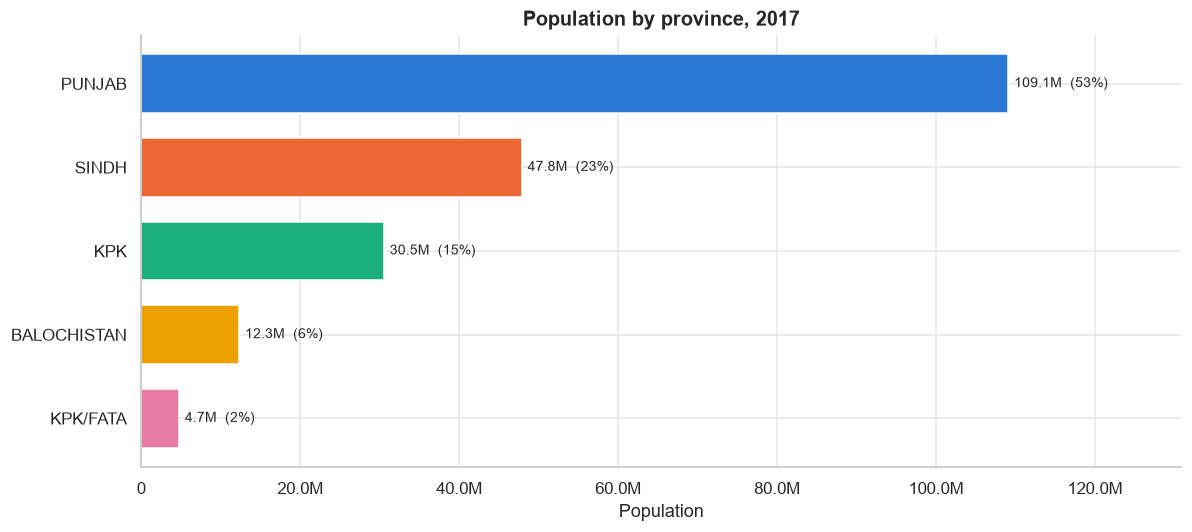

In [8]:
fig, ax = plt.subplots()
hbar(ax, prov.index, prov.POP_2017, [COLOR[p] for p in ORDER], [f"{v/1e6:.1f}M  ({s:.0%})" for v, s in zip(prov.POP_2017, prov.SHARE)])
ax.xaxis.set_major_formatter(HUMAN); ax.set_xlim(0, prov.POP_2017.max() * 1.2)
ax.set(title="Population by province, 2017", xlabel="Population", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:**

- Punjab's bar is by far the longest, at 109.1 million people or 53% of the total. Even if Sindh, KPK, Balochistan and FATA are added together (about 95.3 million), they still fall short of Punjab alone.
- Sindh is second with 47.8 million (23%) and KPK third with 30.5 million (15%). These three provinces together hold about 92% of all the people in the file.
- Balochistan has only 12.3 million people (6%), even though it covers the largest area of any province, roughly 44% of all the land in this dataset. Its bar is short because its people are spread very thinly, and Plot 3 shows this more clearly.
- KPK/FATA is the smallest bar at 4.7 million (2%). It appears separately only because the census listed it that way. If it were merged with KPK, the province would have about 35.2 million people, close to 17% of the total, and would still rank third.
- Each province keeps the same colour in every later chart: Punjab is blue, Sindh orange, KPK green, Balochistan yellow and FATA pink.
- Because Punjab is so large, any national average is mostly a Punjab average. This is why province-wise charts are more useful than a single national figure.

### Plot 2: Population in 1998 and 2017 (Dumbbell Chart)

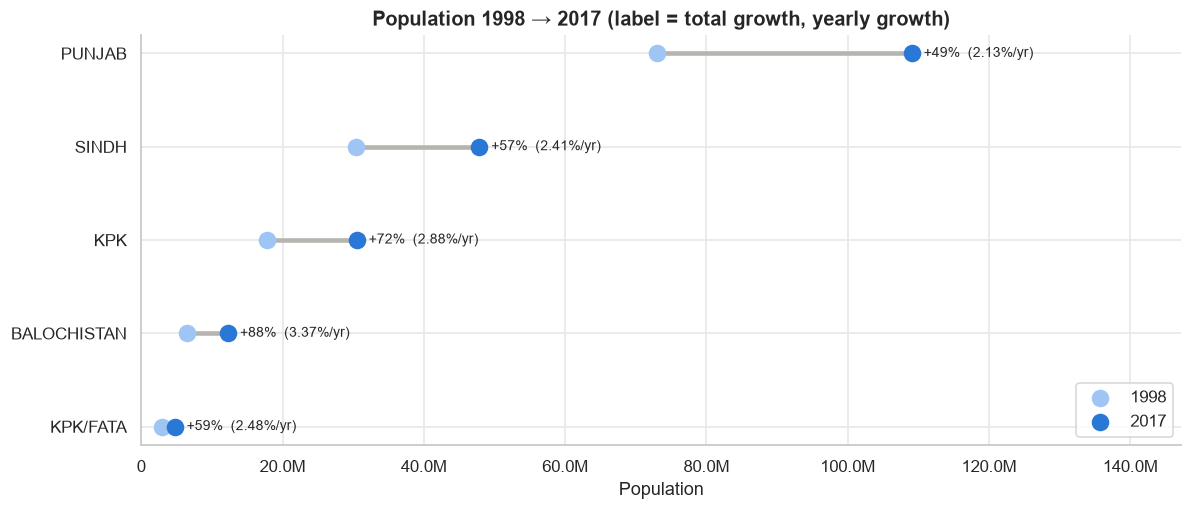

In [9]:
p = prov.sort_values("POP_2017")
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.hlines(p.index, p.POP_1998, p.POP_2017, color="#b5b4ae", lw=3)
ax.scatter(p.POP_1998, p.index, s=110, color="#9ec5f4", label="1998", zorder=3)
ax.scatter(p.POP_2017, p.index, s=110, color=PALETTE[0], label="2017", zorder=3)
for prv, r in p.iterrows():
    ax.text(r.POP_2017, prv, f"   +{r.POP_2017/r.POP_1998-1:.0%}  ({r.CAGR:.2f}%/yr)", va="center", fontsize=9)
ax.xaxis.set_major_formatter(HUMAN); ax.set_xlim(0, p.POP_2017.max() * 1.35)
ax.set(title="Population 1998 → 2017 (label = total growth, yearly growth)", xlabel="Population")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Interpretation:**

- Each province has two dots. The light blue dot is the 1998 population and the dark blue dot is 2017. The grey line joining them shows how much the province grew, and the label gives the total increase and the yearly growth rate.
- Balochistan grew fastest in relative terms. It went from 6.5 million to 12.3 million, a rise of 88% or 3.37% a year, so its population almost doubled in 19 years.
- KPK is next with +72% (2.88% a year), then KPK/FATA with +59% (2.48%) and Sindh with +57% (2.41%). Punjab is last with +49% (2.13% a year).
- Punjab is the only province growing more slowly than the national rate of 2.38%. Sindh sits almost exactly on that rate.
- The head-count tells a different story from the percentages. Punjab's grey line is the longest on the axis because it added about 36.0 million people, close to half (49%) of all the new people in the country. Sindh added 17.4 million, KPK 12.7 million, Balochistan 5.7 million and FATA 1.8 million.
- The balance has shifted a little over the years. Punjab's share of the national population fell from 55.8% in 1998 to 53.4% in 2017, while Balochistan rose from 5.0% to 6.0% and KPK from 13.6% to 14.9%.
- A dumbbell chart works better here than two bars per province, because the length of the line shows the change directly. The two FATA dots almost overlap because its population is small on this scale.

### Plot 3: Population Density by Province

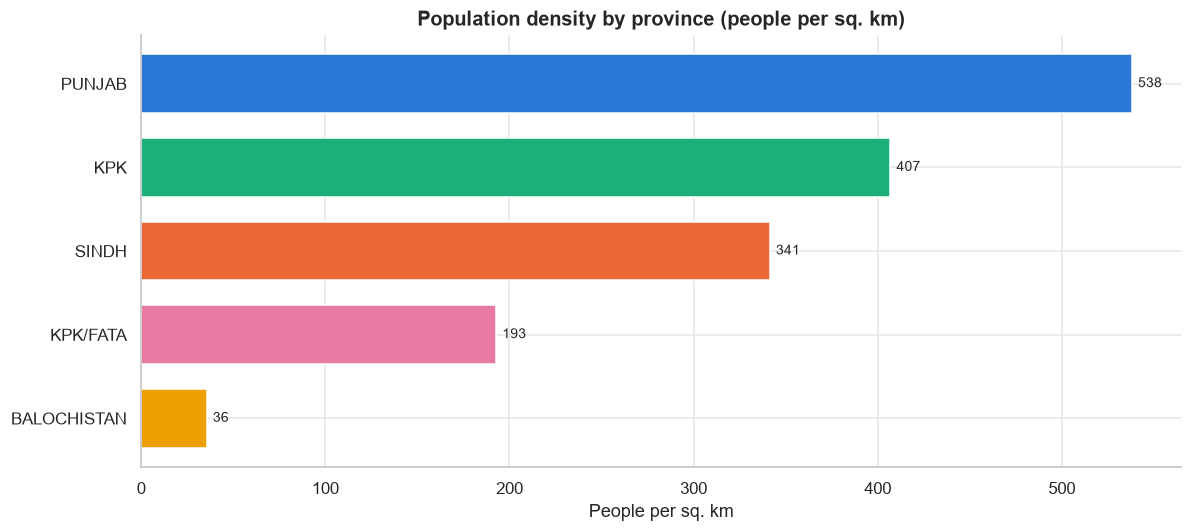

Pakistan average: 259 people/sq.km (4 Killa Saifullah tehsils with unknown area excluded)


In [10]:
dens = (prov.POP_2017 / prov.AREA).sort_values(ascending=False)
fig, ax = plt.subplots()
hbar(ax, dens.index, dens.values, [COLOR[p] for p in dens.index], [f"{v:.0f}" for v in dens.values])
ax.set(title="Population density by province (people per sq. km)", xlabel="People per sq. km", ylabel="")
plt.tight_layout(); plt.show()
print("Pakistan average:", round(df.POP_2017.sum() / df["AREA (SQ.KM)"].sum()), "people/sq.km",
      "(4 Killa Saifullah tehsils with unknown area excluded)")

**Interpretation:**

- Density is each province's total population divided by its total area, so big and small tehsils are weighted correctly. Punjab is the most crowded with 538 people per sq. km, followed by KPK (407), Sindh (341), KPK/FATA (193) and Balochistan (36). The national figure is about 259.
- Only Punjab, KPK and Sindh are above the national figure. FATA and Balochistan are well below it.
- The order is not the same as in Plot 1. Sindh has the second-largest population but only the third-highest density, because its area (about 140,000 sq. km) is almost twice that of KPK (about 75,000 sq. km). KPK fits 30.5 million people into a much smaller space.
- Balochistan sits at the bottom with roughly 15 times fewer people per sq. km than Punjab. Most of the province is desert or mountains, and settlements are small and far apart. This makes roads, schools and clinics expensive to provide for each person served.
- Provincial density can hide a lot. Sindh's number is pulled up by the extremely crowded districts of Karachi, so most of the province is less crowded than 341 suggests (Plot 10 shows the district picture).
- The four Killa Saifullah tehsils with unknown area no longer appear as infinitely dense, which was the problem described in Section 2.

## 5. Urban and Rural Population

### Plot 4: Urban and Rural Share in Each Province (100% Stacked Bar)

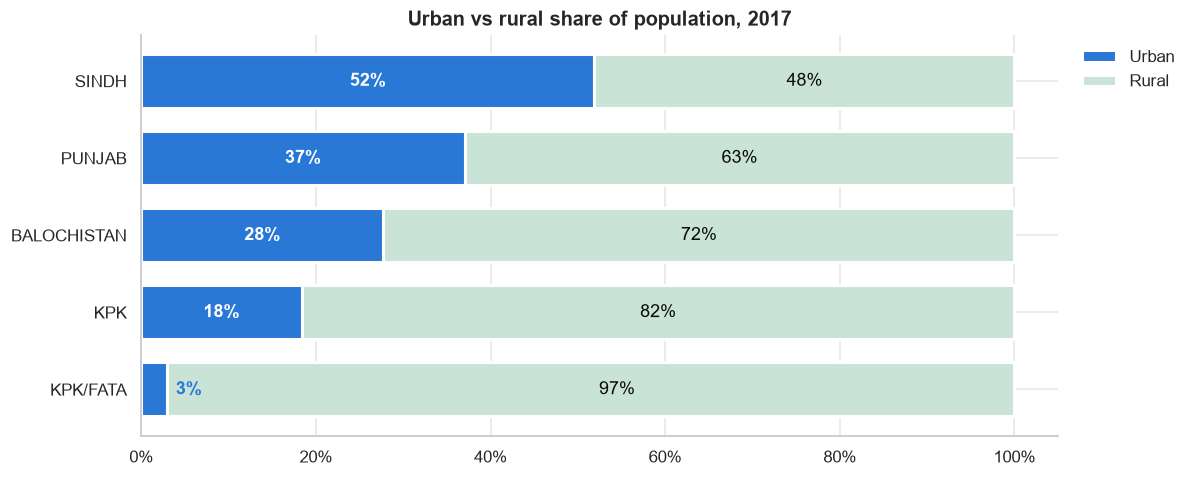

In [11]:
ur = pd.DataFrame({"Urban": prov.URBAN_2017 / prov.POP_2017, "Rural": prov.RURAL_2017 / prov.POP_2017})
ur = ur.sort_values("Urban")
ax = ur.plot.barh(stacked=True, color=[PALETTE[0], "#c9e3d7"], width=.7, edgecolor="white", linewidth=2, figsize=(11, 4.5))
for i, (u, r) in enumerate(ur.values):
    if u > .06: ax.text(u / 2, i, f"{u:.0%}", ha="center", va="center", color="white", fontweight="bold")
    else:       ax.text(u + .01, i, f"{u:.0%}", ha="left", va="center", color=PALETTE[0], fontweight="bold")
    ax.text(u + r / 2 + (.03 if u <= .06 else 0), i, f"{r:.0%}", ha="center", va="center", color="#0b0b0b")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Urban vs rural share of population, 2017", xlabel="", ylabel="")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False); plt.tight_layout(); plt.show()

**Interpretation:**

- Every bar adds up to 100% of a province's people. Blue is urban, light green is rural, and the bars are sorted by urban share.
- Sindh is the only province where more than half of the people (52%) live in urban areas. Karachi has about 16.0 million people, which is roughly a third of Sindh's population and about 60% of its urban population. Hyderabad adds to this.
- Punjab is 37% urban and 63% rural, very close to the national split of 36%. Balochistan is 28% urban and KPK only 18%. KPK's low figure suggests that its people live mainly in villages and small towns rather than in big cities.
- KPK/FATA is almost entirely rural (97%). Only about 140,000 of its 4.7 million people live in urban areas.
- Percentages can hide size. Punjab's rural population (68.7 million) is larger than the entire population of Sindh (47.8 million).
- The national figure of 36% covers a wide range, from 3% in FATA to 52% in Sindh. Outside Sindh, Pakistan is still a country of villages.

### Plot 5: Change in Urban Share, 1998 to 2017 (Slope Chart)

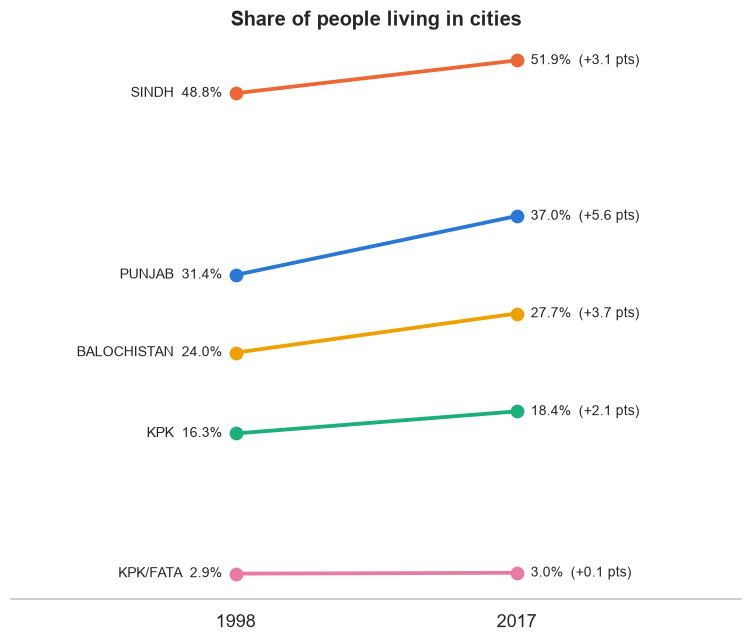

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
for prv, r in prov.iterrows():
    ax.plot([0, 1], [r["URBAN_%_1998"], r["URBAN_%_2017"]], marker="o", lw=2.5, ms=8, color=COLOR[prv])
    ax.text(-0.05, r["URBAN_%_1998"], f"{prv}  {r['URBAN_%_1998']:.1f}%", ha="right", va="center", fontsize=9)
    ax.text(1.05, r["URBAN_%_2017"], f"{r['URBAN_%_2017']:.1f}%  ({r['URBAN_%_2017']-r['URBAN_%_1998']:+.1f} pts)", ha="left", va="center", fontsize=9)
ax.set_xticks([0, 1]); ax.set_xticklabels(["1998", "2017"], fontsize=12); ax.set_xlim(-0.8, 1.8)
ax.set_yticks([]); ax.grid(False); ax.spines["left"].set_visible(False)
ax.set_title("Share of people living in cities")
plt.tight_layout(); plt.show()

**Interpretation:**

- Each line follows one province from 1998 (left) to 2017 (right). A steeper line means faster urbanisation, and the labels give the values and the change in percentage points.
- Punjab has the steepest line. Its urban share rose from 31.4% to 37.0%, a gain of 5.6 points. Balochistan gained 3.7 points (24.0% to 27.7%), Sindh 3.1 points (48.8% to 51.9%) and KPK 2.1 points (16.3% to 18.4%).
- KPK/FATA is almost flat, moving only from 2.9% to 3.0%. Hardly any urbanisation took place there.
- Sindh crossed the 50% mark between the two censuses. In 1998 fewer than half of its people were urban, and in 2017 more than half were.
- None of the lines cross, so the ranking is the same in both years: Sindh, Punjab, Balochistan, KPK and FATA.
- For the whole country the urban share rose by 4.0 points in 19 years, which is about 0.2 points a year. At that pace Pakistan would need well over half a century to become half urban.
- One caution: this chart cannot say whether the rise comes from people moving to cities or from villages being reclassified as towns. The dataset does not separate the two.

### Plot 6: Urban and Rural Growth per Year

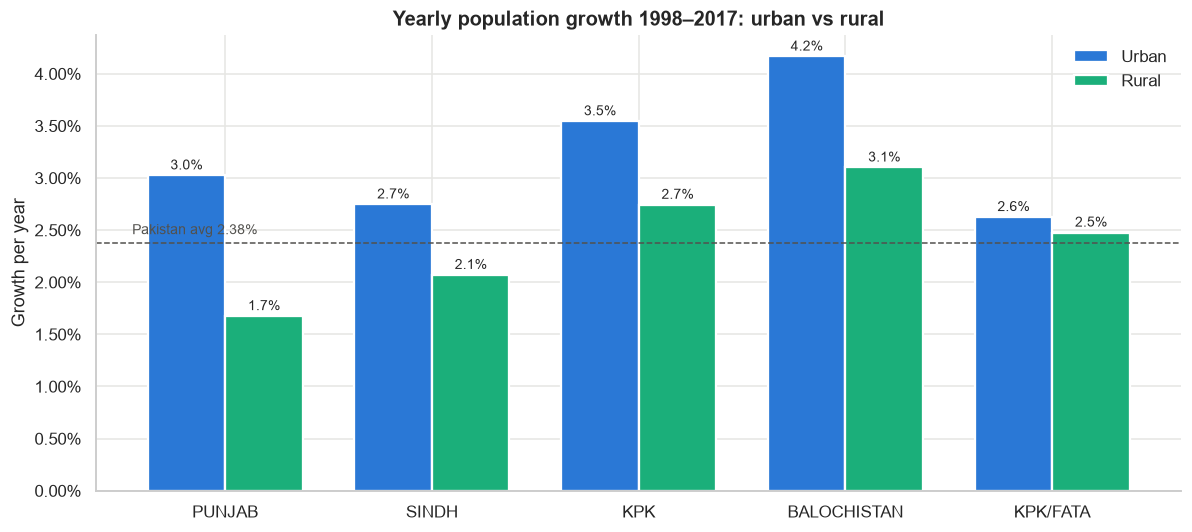

In [13]:
g = prov[["URBAN_CAGR", "RURAL_CAGR"]].rename(columns={"URBAN_CAGR": "Urban", "RURAL_CAGR": "Rural"})
ax = g.plot.bar(color=[PALETTE[0], PALETTE[2]], width=.75, edgecolor="white", linewidth=1.5, figsize=(11, 5))
for c in ax.containers: ax.bar_label(c, fmt="%.1f%%", fontsize=9, padding=2)
ax.axhline(cagr(P17, P98), color="#52514e", ls="--", lw=1)
ax.text(-0.45, cagr(P17, P98) + 0.08, f"Pakistan avg {cagr(P17, P98):.2f}%", ha="left", fontsize=9, color="#52514e")
ax.tick_params(axis="x", rotation=0); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set(title="Yearly population growth 1998–2017: urban vs rural", xlabel="", ylabel="Growth per year")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Interpretation:**

- Blue bars show urban growth and green bars show rural growth for each province. The dashed line marks the national growth rate of 2.38% a year.
- In every province the urban bar is taller than the rural bar, so cities grew faster than villages everywhere. Nationally, urban population grew at 3.0% a year against 2.05% for rural areas.
- Punjab has the widest gap, with urban growth of 3.0% and rural growth of only 1.7%. Rural Punjab is the slowest-growing group on the whole chart. Slower natural growth in villages and people moving out to the cities can both play a part, but this data cannot tell us how much each contributes.
- Balochistan has the highest bars for both groups, 4.2% urban and 3.1% rural. Its cities, led by Quetta, are growing faster than any other province's cities. KPK follows with 3.5% urban and 2.7% rural.
- Every urban bar sits above the dashed line. Only two rural bars, Punjab (1.7%) and Sindh (2.1%), fall below it.
- In KPK/FATA the two bars are almost equal (2.6% and 2.5%). This fits with Plot 5, where its urban share barely changed.

## 6. How the Population Is Spread

### Plot 7: Size of Tehsils (Histogram)

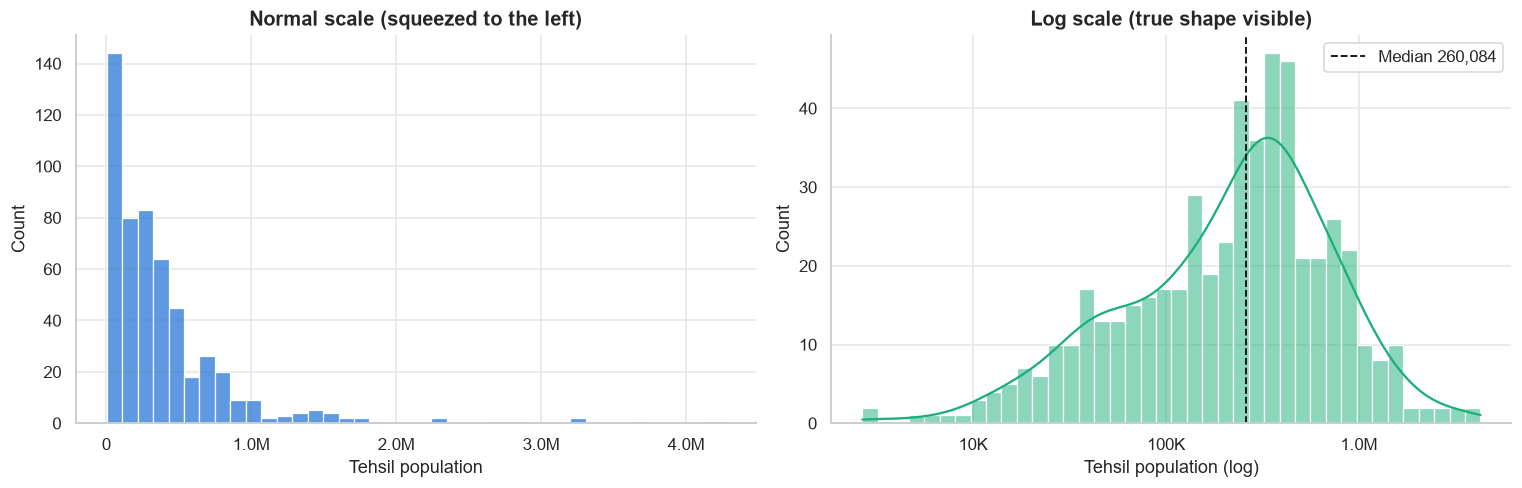

count          528
mean       387,142
std        477,957
min          2,665
25%         98,452
50%        260,084
75%        460,310
90%        846,193
max      4,267,198


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.histplot(df.POP_2017, bins=40, color=PALETTE[0], ax=axes[0])
axes[0].xaxis.set_major_formatter(HUMAN); axes[0].set(title="Normal scale (squeezed to the left)", xlabel="Tehsil population")
sns.histplot(df.POP_2017, bins=40, log_scale=True, kde=True, color=PALETTE[2], ax=axes[1])
axes[1].axvline(df.POP_2017.median(), color="#0b0b0b", ls="--", lw=1.2, label=f"Median {df.POP_2017.median():,.0f}")
axes[1].xaxis.set_major_formatter(HUMAN); axes[1].set(title="Log scale (true shape visible)", xlabel="Tehsil population (log)")
axes[1].legend(); plt.tight_layout(); plt.show()
print(df.POP_2017.describe(percentiles=[.25, .5, .75, .9]).apply(lambda v: f"{v:,.0f}").to_string())

**Interpretation:**

- The left panel uses a normal scale. Most tehsils are bunched on the left, with about 144 in the first bar alone, and a thin tail stretches out to 4.27 million. This is a right-skewed distribution, which means a few giant tehsils drag the axis out.
- The right panel uses a log scale, which spreads the small values out so that the real shape is visible. The range is so large (from 2,665 to 4.27 million) that a normal scale cannot show it properly.
- On the log scale the histogram has two humps. A smaller shoulder appears at roughly 30,000 to 60,000 people, and the main peak is at roughly 400,000 to 600,000, with about 47 tehsils in the tallest bar. Plot 8 suggests that the first group is made up of small tehsils in Balochistan and the tribal areas, and the second of large Punjab tehsils.
- The median is 260,084 people, while the mean is 387,142. The mean is about 49% higher because a few huge tehsils pull it up, so the median is the fairer description of a typical tehsil.
- About 52% of tehsils have between 100,000 and 500,000 people. Around 133 tehsils (a quarter of the total) have fewer than 100,000, and 35 tehsils have more than a million. Thirty of those 35 are in Punjab.
- Because the data really comes from two different kinds of tehsil, even the median hides something. It describes the middle tehsil but does not describe either group well.

### Plot 8: Tehsil Size in Each Province (Box Plot)

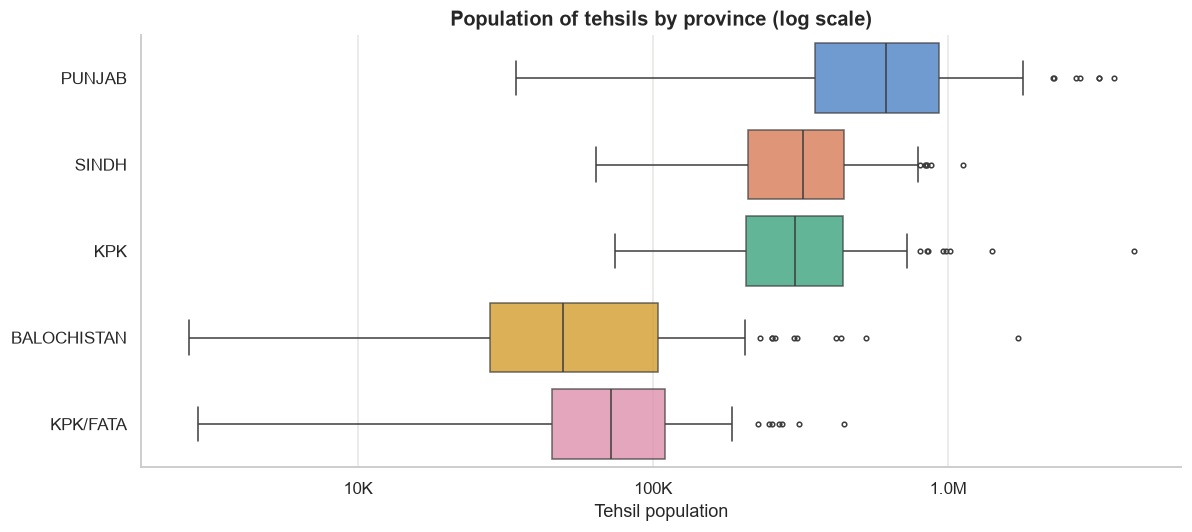

PROVINCE
PUNJAB         613,305
SINDH          322,376
KPK            303,644
BALOCHISTAN     49,480
KPK/FATA        71,754


In [15]:
plt.figure(figsize=(11, 5))
ax = sns.boxplot(data=df, x="POP_2017", y="PROVINCE", order=ORDER, palette=COLOR, fliersize=3, boxprops=dict(alpha=.75))
ax.set_xscale("log"); ax.xaxis.set_major_formatter(HUMAN)
ax.set(title="Population of tehsils by province (log scale)", xlabel="Tehsil population", ylabel="")
plt.tight_layout(); plt.show()
print(df.groupby("PROVINCE")["POP_2017"].median().reindex(ORDER).apply(lambda v: f"{v:,.0f}").to_string())

**Interpretation:**

- Each box covers the middle half of a province's tehsils, the line inside it is the median, the whiskers show the normal range and the dots are unusually large or small tehsils. The axis is on a log scale.
- Punjab's tehsils are the biggest, with a median of about 613,000 people. Sindh (322,000) and KPK (304,000) are close to each other, with boxes that almost overlap, which means their tehsils are fairly similar in size.
- Balochistan's median is only about 49,000 and KPK/FATA's is about 72,000. Punjab's typical tehsil is therefore about 12 times the size of Balochistan's.
- Balochistan has 131 tehsils, almost as many as Punjab's 143, yet only about 11% of Punjab's population. The province is divided into many small units spread over a huge area.
- Balochistan and FATA have the widest boxes and whiskers, so their tehsils vary enormously in size, from under 3,000 to a few hundred thousand people.
- The dots on the right side tell their own story. Punjab's highest dots are big city tehsils such as Lahore City (3.65 million), Rawalpindi (3.26 million) and Faisalabad City (3.24 million). The far right dot in KPK is Peshawar Tehsil at 4.27 million, which is bigger than any tehsil in Punjab. Balochistan's lone high dot is Quetta City Tehsil at about 1.7 million.
- A tehsil is clearly not a uniform unit. Comparing tehsil-level numbers across provinces, or planning services for each tehsil, can be misleading unless size is considered.

In [16]:
# District-level table used by the next plots
dist = df.groupby(["PROVINCE", "DISTRICT"]).agg(POP_2017=("POP_2017", "sum"), POP_1998=("POP_1998", "sum"),
                                                URBAN_2017=("URBAN_2017", "sum"), AREA=("AREA (SQ.KM)", lambda s: s.sum(min_count=len(s))),
                                                MALE=("MALE", "sum"), FEMALE=("FEMALE", "sum"),
                                                HH=("HH_RURAL", "sum"), HH_U=("HH_URBAN", "sum")).reset_index()
dist["NAME"] = dist.DISTRICT.str.replace(" DISTRICT", "").str.title()
dist["CAGR"] = cagr(dist.POP_2017, dist.POP_1998)
dist["URBAN_%"] = dist.URBAN_2017 / dist.POP_2017 * 100
dist["DENSITY"] = dist.POP_2017 / dist.AREA          # NaN where area is unknown
dist["SEX_RATIO"] = dist.MALE / dist.FEMALE * 100
dist["HH_SIZE"] = dist.POP_2017 / (dist.HH + dist.HH_U)
print("Districts:", len(dist))

Districts: 131


### Plot 9: The 15 Most Populated Districts

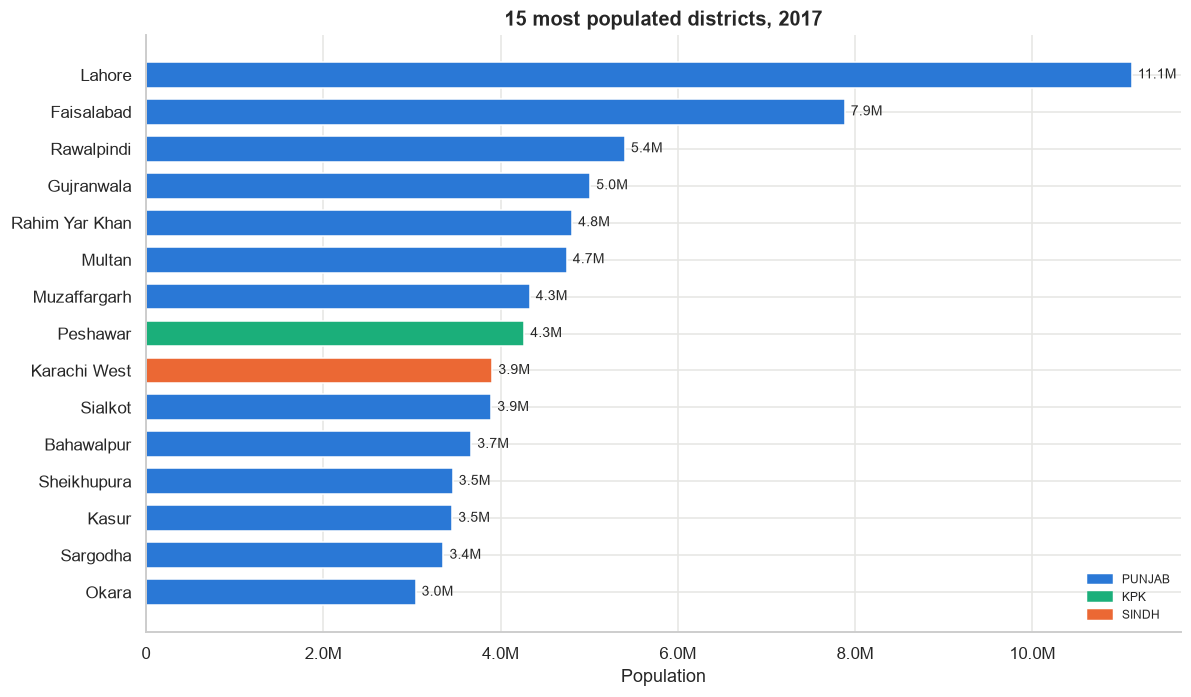

In [17]:
top = dist.nlargest(15, "POP_2017")
fig, ax = plt.subplots(figsize=(11, 6.5))
hbar(ax, top.NAME, top.POP_2017, top.PROVINCE.map(COLOR), [f"{v/1e6:.1f}M" for v in top.POP_2017], legend=top.PROVINCE.unique())
ax.xaxis.set_major_formatter(HUMAN)
ax.set(title="15 most populated districts, 2017", xlabel="Population", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:**

- Lahore has the longest bar by a wide margin at 11.1 million people, about 5.4% of the whole dataset. Faisalabad is second with 7.9 million, so Lahore is about 1.4 times its size. Rawalpindi follows with 5.4 million, then Gujranwala (5.0 million), Rahim Yar Khan (4.8 million) and Multan (4.7 million).
- The colours show how Punjab-heavy the list is. Thirteen of the fifteen bars are blue (Punjab). The only exceptions are Peshawar (KPK, 4.3 million) and Karachi West (Sindh, 3.9 million). Balochistan has no district in the list, and its largest, Quetta, has about 2.3 million.
- Not all of Punjab's entries are big cities. Rahim Yar Khan, Muzaffargarh and Okara are less than 30% urban, so they are on the list because of large rural populations rather than large cities.
- Karachi looks small here only because it is split into six districts: West (3.9 million), Central (3.0 million), East (2.9 million), Korangi (2.6 million), Malir (1.9 million) and South (1.8 million). Added together they come to 16.0 million, about 44% more than Lahore.
- In this file the Peshawar district has a single tehsil, so Peshawar Tehsil and Peshawar District show the same figure of 4,267,198. This is why the largest tehsil in Plot 8 also appears here.
- District rankings depend on how boundaries were drawn. Merging or splitting a district can change its rank without any change in the number of people.

### Plot 10: The 12 Most Densely Populated Districts (Log Scale)

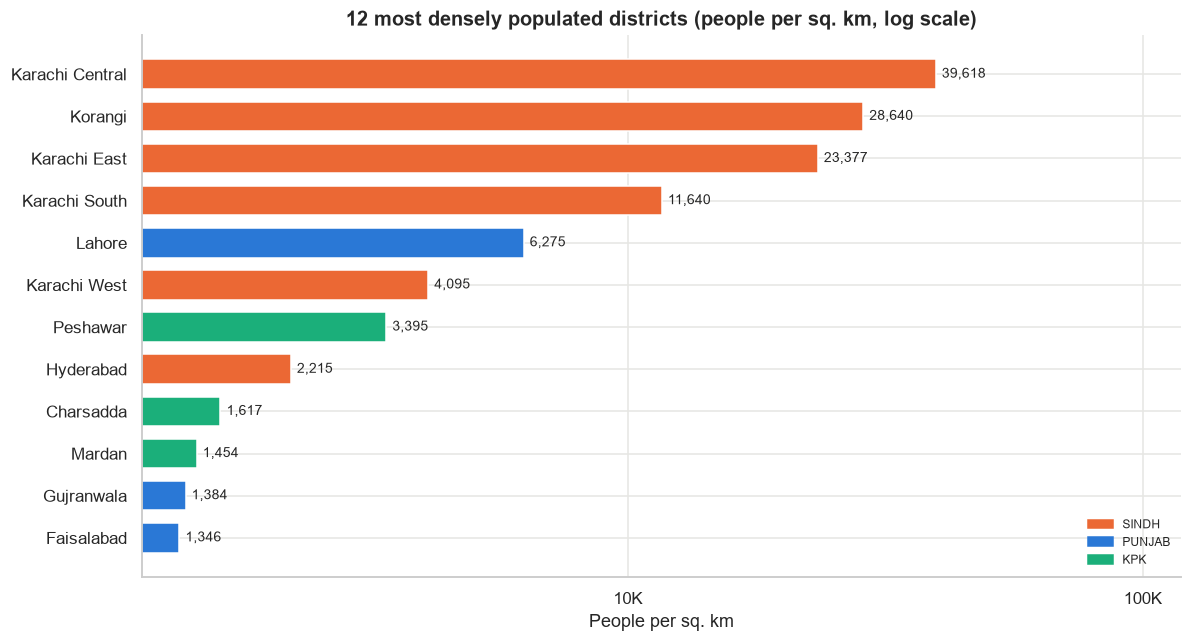

In [18]:
d = dist.dropna(subset=["DENSITY"]).nlargest(12, "DENSITY")
fig, ax = plt.subplots(figsize=(11, 6))
hbar(ax, d.NAME, d.DENSITY, d.PROVINCE.map(COLOR), [f"{v:,.0f}" for v in d.DENSITY], legend=d.PROVINCE.unique())
ax.set_xscale("log"); ax.xaxis.set_major_formatter(HUMAN); ax.set_xlim(right=d.DENSITY.max() * 3)
ax.set(title="12 most densely populated districts (people per sq. km, log scale)", xlabel="People per sq. km", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:**

- The axis is logarithmic, so each gridline is ten times the previous one. Without this, Karachi Central would dwarf every other bar and the rest would be almost invisible.
- Karachi Central is the most crowded district at about 39,600 people per sq. km. Korangi (28,640), Karachi East (23,377) and Karachi South (11,640) follow, so the first four places all belong to Karachi. Lahore is fifth at 6,275.
- Five of Karachi's districts are in the top six, and Sindh has six of the twelve bars in total, since Hyderabad (2,215) is also included. Punjab has three (Lahore, Gujranwala and Faisalabad) and KPK has three (Peshawar, Charsadda and Mardan).
- Karachi Central is about 6 times denser than Lahore, about 29 times denser than Faisalabad and more than 1,000 times denser than Balochistan as a whole (36 per sq. km).
- Lahore is the only Punjab district above 2,000 people per sq. km. Gujranwala and Faisalabad are only around 1,300 to 1,400.
- Charsadda (1,617) and Mardan (1,454) show that crowding in KPK is not limited to its main city. Small districts around Peshawar are also densely settled.
- Such crowding puts heavy pressure on water supply, transport, schools and hospitals, which matters for planning.

### Plot 11: Fastest and Slowest Growing Districts

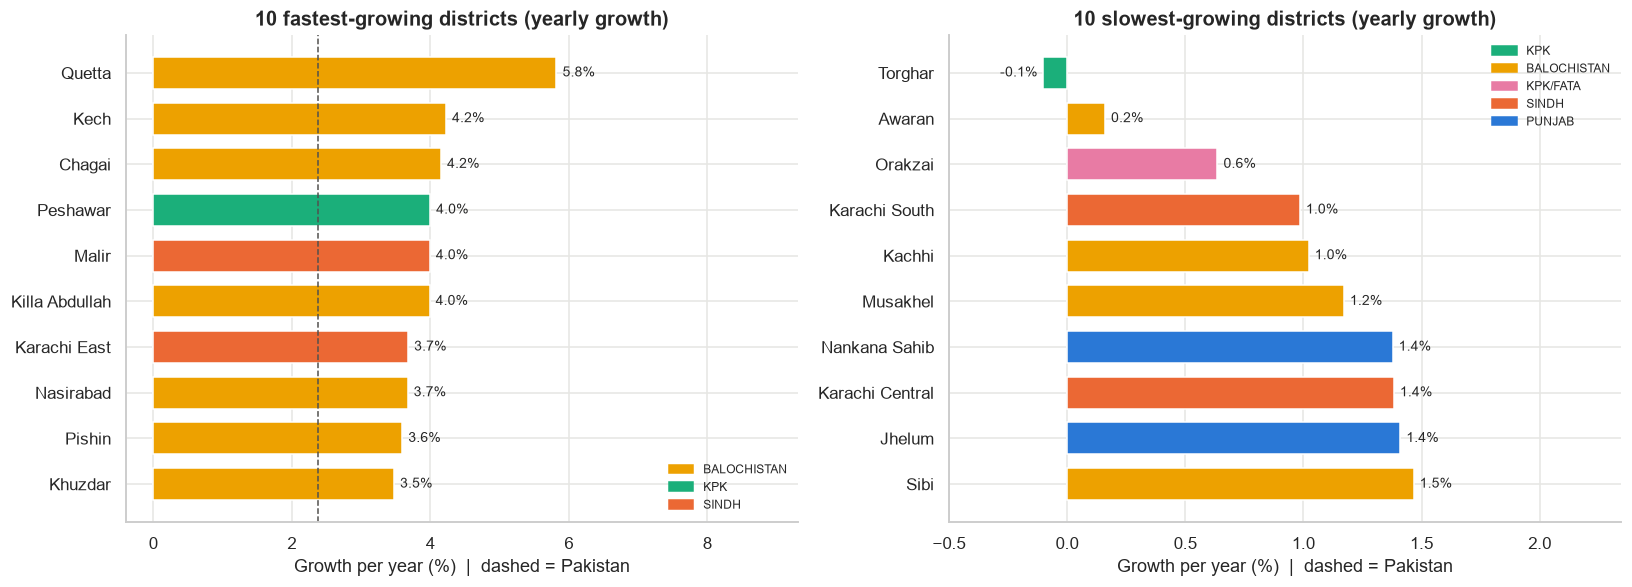

In [19]:
big = dist[dist.POP_1998 >= 100_000]                 # ignore very small districts (unstable %)
fast, slow = big.nlargest(10, "CAGR"), big.nsmallest(10, "CAGR")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, data, title, loc in [(axes[0], fast, "10 fastest-growing districts", "lower right"), (axes[1], slow, "10 slowest-growing districts", "upper right")]:
    hbar(ax, data.NAME, data.CAGR, data.PROVINCE.map(COLOR), [f"{v:.1f}%" for v in data.CAGR], legend=data.PROVINCE.unique(), loc=loc)
    ax.axvline(cagr(P17, P98), color="#52514e", ls="--", lw=1)
    ax.set_xlim(min(0, data.CAGR.min()) - 0.4, data.CAGR.max() * 1.6)
    ax.set(title=title + " (yearly growth)", xlabel="Growth per year (%)  |  dashed = Pakistan", ylabel="")
plt.tight_layout(); plt.show()

**Interpretation:**

- The left panel shows the ten fastest-growing districts and the right panel the ten slowest. The two panels use different scales. Districts with fewer than 100,000 people in 1998 are left out, because a very small starting population makes growth percentages unreliable.
- The dashed line (national growth of 2.38%) is drawn on the left panel. On the right panel it falls outside the axis, which means all ten slowest districts are well below the national rate.
- Quetta is the clear leader at 5.8% a year. Its population rose from about 775,000 to 2.27 million, nearly tripling in 19 years, and its growth rate is about 2.4 times the national rate. Kech and Chagai (4.2%) come next, followed by Peshawar, Malir and Killa Abdullah at about 4.0%.
- Seven of the ten fastest districts are in Balochistan (Quetta, Kech, Chagai, Killa Abdullah, Nasirabad, Pishin and Khuzdar). Peshawar and the two Karachi districts, Malir and Karachi East, complete the list.
- Torghar is the only district that shrank (-0.1% a year), and Awaran barely grew (0.2%). Orakzai (0.6%) is third from the bottom. The data cannot tell us why, so explanations such as out-migration or displacement would need other sources.
- Karachi appears on both sides. Malir and Karachi East are among the fastest, while Karachi South (1.0%) and Karachi Central (1.4%) are among the slowest. The older central districts seem to be full, and growth is moving to the outer areas.
- Balochistan also appears on both sides, with four districts among the slowest (Awaran, Kachhi, Musakhel and Sibi). This shows that the province's high average growth comes from particular districts and not from the whole province.
- Punjab's two entries on the slow side, Nankana Sahib and Jhelum (both 1.4%), match the low growth of rural Punjab in Plot 6.

### Plot 12: Cumulative Share of Population by District (Pareto Curve)

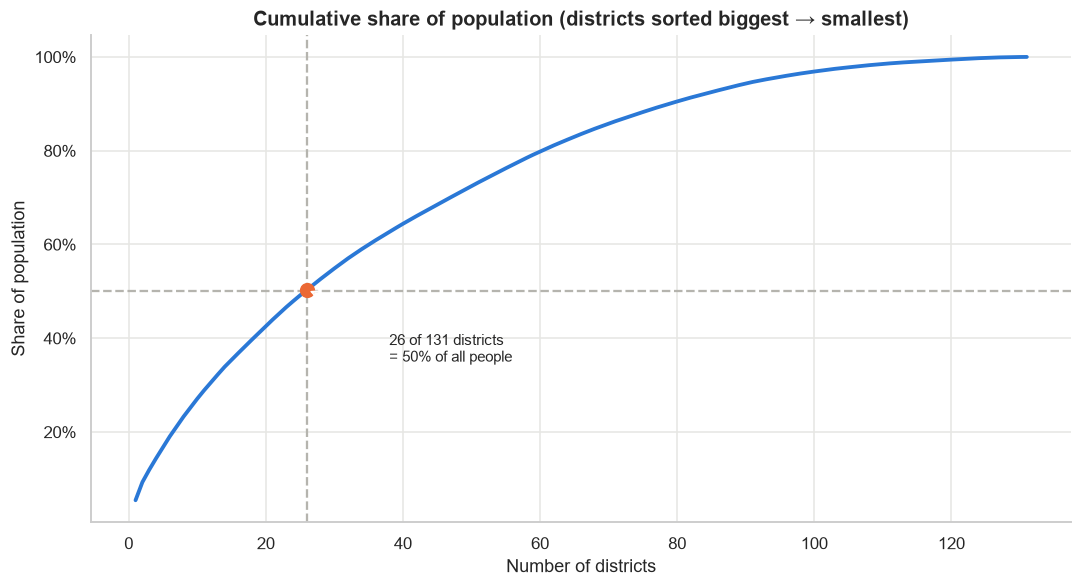

Top 10 districts hold 27% of the population


In [20]:
s = dist.POP_2017.sort_values(ascending=False).reset_index(drop=True)
cum = s.cumsum() / s.sum()
n50 = int((cum < .5).sum() + 1)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(np.arange(1, len(s) + 1), cum, color=PALETTE[0], lw=2.5)
ax.axhline(.5, color="#b5b4ae", ls="--"); ax.axvline(n50, color="#b5b4ae", ls="--")
ax.scatter([n50], [cum[n50 - 1]], s=80, color=PALETTE[1], zorder=3)
ax.annotate(f"{n50} of {len(s)} districts\n= 50% of all people", (n50, cum[n50 - 1]), xytext=(n50 + 12, .35),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Cumulative share of population (districts sorted biggest → smallest)", xlabel="Number of districts", ylabel="Share of population")
plt.tight_layout(); plt.show()
print(f"Top 10 districts hold {cum[9]:.0%} of the population")

**Interpretation:**

- Districts are sorted from largest to smallest along the horizontal axis, and the line shows the running share of the population they hold. If people were spread evenly, the line would be straight. Instead it climbs steeply and then flattens, which means the population is concentrated.
- The orange point marks the key result. Only 26 of 131 districts (about 20%) hold half of all people.
- The top 5 districts hold about 17% of the population, the top 10 hold 27%, the top 40 hold about 64% and the top 60 hold about 80%.
- At the other end, the smallest 65 districts, which is half of all districts, hold only about 16% of the population, and the smallest 50 hold about 9%.
- After the 60th district the curve is almost flat. The remaining 71 districts add only about 20% more people.
- This has two meanings for planning. Services built for the top 26 districts would reach half the country. The other 105 districts, however, hold the other half and most of the land, so serving them costs more per person.
- Karachi's six-way split affects this result. As one unit, Karachi would hold about 7.8% of the population on its own, and slightly fewer than 26 units would be needed to reach half.

### Plot 13: Urban Share and Growth in Districts (Bubble Chart)

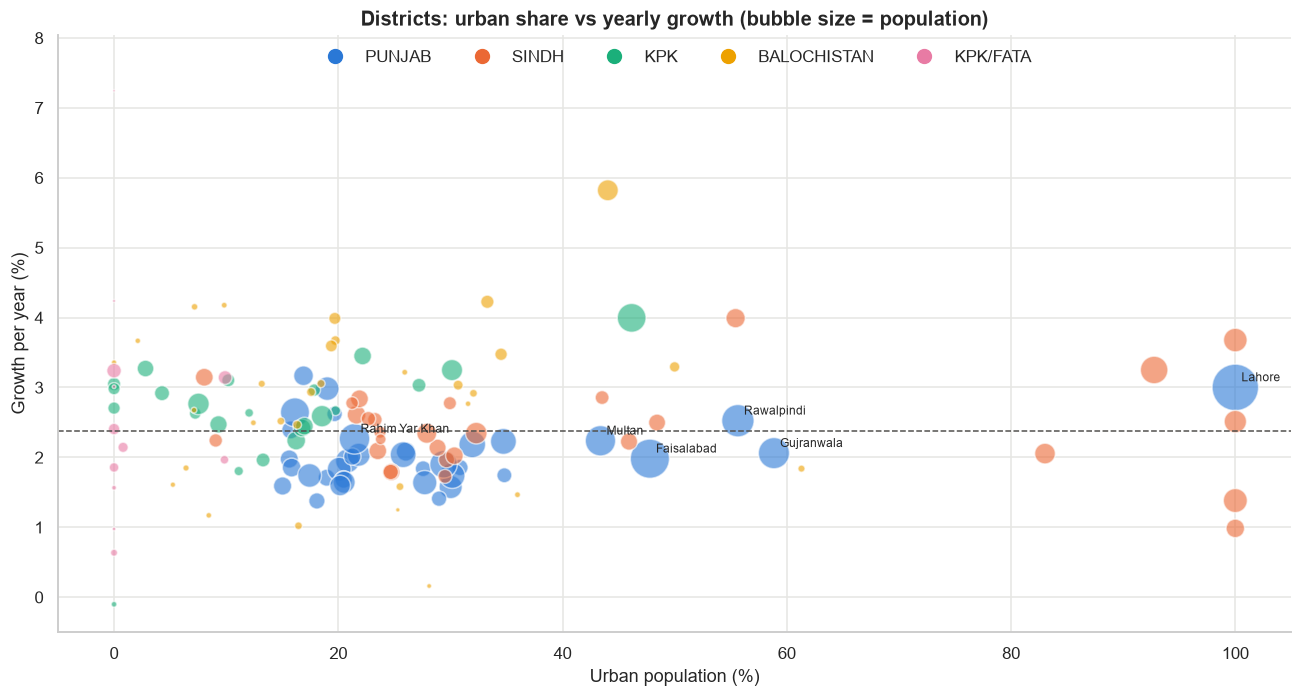

Spearman correlation (urban % vs growth): -0.07


In [21]:
fig, ax = plt.subplots(figsize=(12, 6.5))
for prv in ORDER:
    sub = dist[dist.PROVINCE == prv]
    ax.scatter(sub["URBAN_%"], sub.CAGR, s=sub.POP_2017 / 12_000, color=COLOR[prv], alpha=.6, edgecolor="white", label=prv)
for _, r in dist.nlargest(6, "POP_2017").iterrows():
    ax.annotate(r.NAME, (r["URBAN_%"], r.CAGR), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.axhline(cagr(P17, P98), color="#52514e", ls="--", lw=1)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=9, color=COLOR[p], label=p) for p in ORDER], frameon=False, loc="upper center", ncol=5)
ax.set_ylim(dist.CAGR.min() - .4, dist.CAGR.max() + .8)
ax.set(title="Districts: urban share vs yearly growth (bubble size = population)", xlabel="Urban population (%)", ylabel="Growth per year (%)")
plt.tight_layout(); plt.show()
print("Spearman correlation (urban % vs growth):", round(dist["URBAN_%"].corr(dist.CAGR, method="spearman"), 2))

**Interpretation:**

- Each bubble is a district. Moving right means a higher urban share, moving up means faster growth, a bigger bubble means more people, and the colour shows the province. The dashed line is the national growth rate.
- The cloud has no slope in either direction. The correlation is -0.07, which is practically zero. Districts with more urban people do not grow faster by that fact alone.
- The clearest proof is the column at 100% urban. Lahore (3.0%), Karachi East (3.7%), Korangi (2.5%), Karachi Central (1.4%) and Karachi South (1.0%) are all fully urban, yet their growth rates are spread from 1.0% to 3.7%.
- Punjab's blue bubbles form a tight group between roughly 15% and 35% urban, with growth between about 1.5% and 2.5%, mostly at or just under the dashed line. Among the large Punjab cities, Rawalpindi (2.5%), Multan (2.2%), Gujranwala (2.1%) and Faisalabad (2.0%) are close to the line (Rawalpindi just above it, the other three just below), while Lahore (3.0%) is clearly above it.
- Quetta is the highest bubble at 5.8% with an urban share of about 44%. Peshawar (46% urban, 4.0%) and Malir (55% urban, 4.0%) are also well above the line.
- Balochistan's yellow bubbles are scattered along the whole horizontal axis, and most are above the line. Fourteen districts, mostly in KPK and the former tribal areas, have no urban population at all, and their growth rates run from -0.1% to over 7% (in one very small district). Growth depends more on the region than on how urban a district is.
- The share of districts growing faster than the national rate supports this: 83% in KPK, 71% in Balochistan, 50% in KPK/FATA, 45% in Sindh and only 19% in Punjab.
- A chart should always be checked before assuming a relationship. Here the assumption that cities grow faster does not hold at district level. Overlapping bubbles also hide some of the smaller districts.

## 7. Gender and Households

### Plot 14: Sex Ratio in Rural and Urban Areas

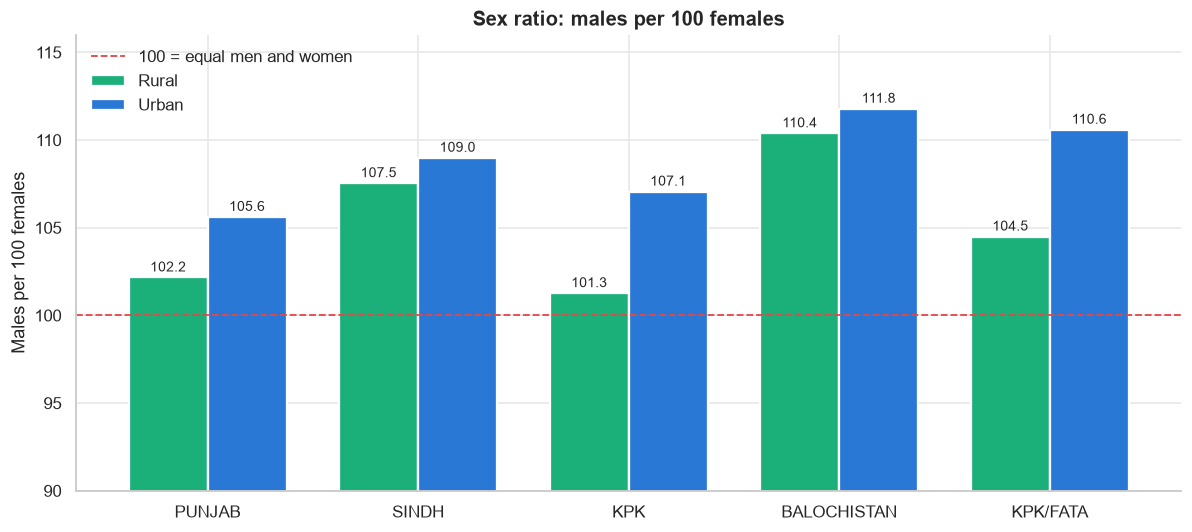

❌ Old wrong method (simple mean, zeros included): {'BALOCHISTAN': 47.6, 'KPK': 59.5, 'KPK/FATA': 15.6, 'PUNJAB': 101.5, 'SINDH': 103.1}
✅ Correct urban sex ratio: {'PUNJAB': 105.6, 'SINDH': 109.0, 'KPK': 107.1, 'BALOCHISTAN': 111.8, 'KPK/FATA': 110.6}


In [22]:
g = df.groupby("PROVINCE")[["MALE (RURAL)", "FEMALE (RURAL)", "MALE (URBAN)", "FEMALE (URBAN)"]].sum()
sr = pd.DataFrame({"Rural": g["MALE (RURAL)"] / g["FEMALE (RURAL)"] * 100,
                   "Urban": g["MALE (URBAN)"] / g["FEMALE (URBAN)"] * 100}).reindex(ORDER)
ax = sr.plot.bar(color=[PALETTE[2], PALETTE[0]], width=.75, edgecolor="white", linewidth=1.5, figsize=(11, 5))
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=9, padding=2)
ax.axhline(100, color="#e34948", ls="--", lw=1.2, label="100 = equal men and women")
ax.set_ylim(90, 116); ax.tick_params(axis="x", rotation=0)
ax.set(title="Sex ratio: males per 100 females", xlabel="", ylabel="Males per 100 females")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()
raw = pd.read_csv("Population-Dataset.csv")
print("❌ Old wrong method (simple mean, zeros included):", raw.groupby("PROVINCE")["SEX RATIO (URBAN)"].mean().round(1).to_dict())
print("✅ Correct urban sex ratio:", sr.Urban.round(1).to_dict())

**Interpretation:**

- Sex ratio means males per 100 females. The red dashed line at 100 marks an equal number of men and women, green bars are rural and blue bars are urban. The vertical axis starts at 90, so differences look bigger than they are, and the printed values are the better guide.
- Every bar is above 100, so there are more men than women in every province, in both rural and urban areas. The national figures are 103.5 for rural areas, 107.1 for urban areas and 104.8 overall.
- Urban areas have more men than rural areas in all five provinces: Punjab 105.6 against 102.2, Sindh 109.0 against 107.5, KPK 107.1 against 101.3, Balochistan 111.8 against 110.4, and KPK/FATA 110.6 against 104.5.
- The gap is largest in KPK/FATA (6.1 points) and KPK (5.8 points). The pattern fits the idea that men move to the cities for work and leave their families in the village. It could also partly reflect women being missed in the count, and this data cannot settle that.
- Balochistan has the highest ratio in both groups (110.4 rural and 111.8 urban). Sindh's rural ratio (107.5) is also high, while KPK's rural ratio (101.3) is close to equal.
- At district level the spread is wider. It runs from 92.3 in Hangu, where women outnumber men, to 123.1 in Sherani.
- The chart also shows why the calculation method matters. A simple average of tehsil values, with the zeros included, would have given 47.6 for Balochistan's urban areas and 15.6 for KPK/FATA's. These figures would mean far more women than men and are plainly wrong. The correct values are 111.8 and 110.6.

### Plot 15: Average Household Size

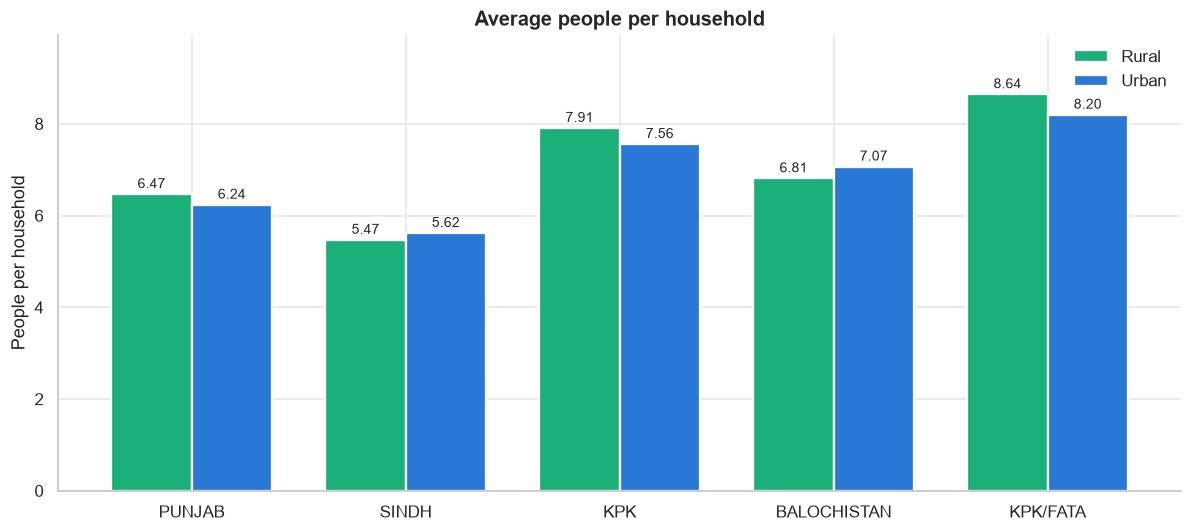

Pakistan: 6.4 people per household


In [23]:
h = df.groupby("PROVINCE").agg(R=("ALL SEXES (RURAL)", "sum"), HR=("HH_RURAL", "sum"), U=("ALL SEXES (URBAN)", "sum"), HU=("HH_URBAN", "sum"))
hh = pd.DataFrame({"Rural": h.R / h.HR, "Urban": h.U / h.HU}).reindex(ORDER)
ax = hh.plot.bar(color=[PALETTE[2], PALETTE[0]], width=.75, edgecolor="white", linewidth=1.5, figsize=(11, 5))
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=9, padding=2)
ax.set_ylim(0, hh.max().max() * 1.15); ax.tick_params(axis="x", rotation=0)
ax.set(title="Average people per household", xlabel="", ylabel="People per household")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
print("Pakistan:", round(df.POP_2017.sum() / (df.HH_RURAL.sum() + df.HH_URBAN.sum()), 2), "people per household")

**Interpretation:**

- Bars show the average number of people per household, green for rural and blue for urban. This axis starts at zero, so the bar heights can be compared directly.
- The national average is 6.4 people per household.
- KPK/FATA has the largest households (8.64 rural, 8.20 urban), followed by KPK (7.91 and 7.56). Balochistan (6.81 and 7.07) and Punjab (6.47 and 6.24) are in the middle, and Sindh has the smallest (5.47 and 5.62).
- The gap between the extremes is big. A rural household in FATA has on average about 3 more people than one in Sindh, which is roughly 58% larger. Joint family living is common in KPK and the tribal areas, which probably explains part of this.
- Urban homes are slightly smaller than rural ones in Punjab, KPK and KPK/FATA, and slightly larger in Sindh and Balochistan. These differences are only about 0.15 to 0.4 people, far smaller than the differences between provinces.
- This means the province matters more than the urban or rural setting. The district data points the same way: Plot 17 shows that more urban districts tend to have smaller households.
- Household sizes at district level run from about 5.0 to 10.3 people. For housing planning, the number of households matters more than the number of people, and a province with larger households needs fewer homes for the same population.

### Plot 16: Transgender Population (Counts and Rate per 100,000)

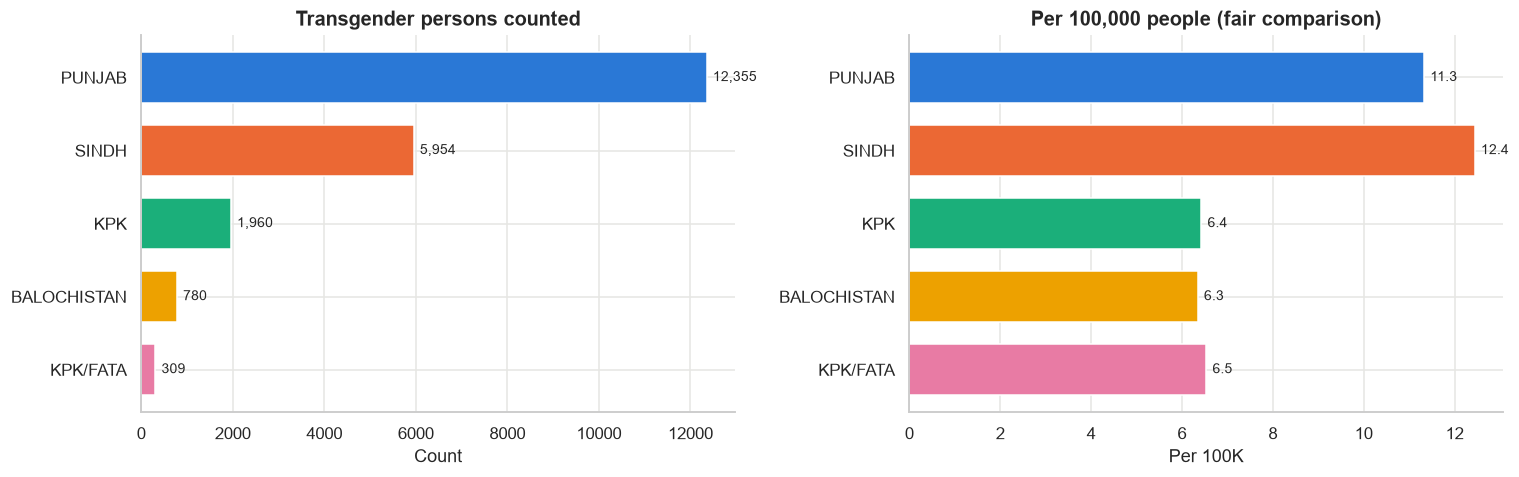

Living in urban areas: 55% of transgender persons vs 36% of all people


In [24]:
t = df.groupby("PROVINCE").agg(TG=("TRANSGENDER", "sum"), POP=("POP_2017", "sum")).reindex(ORDER)
t["PER_100K"] = t.TG / t.POP * 1e5
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
hbar(axes[0], t.index, t.TG, [COLOR[p] for p in t.index], [f"{v:,.0f}" for v in t.TG])
axes[0].set(title="Transgender persons counted", xlabel="Count", ylabel="")
hbar(axes[1], t.index, t.PER_100K, [COLOR[p] for p in t.index], [f"{v:.1f}" for v in t.PER_100K])
axes[1].set(title="Per 100,000 people (fair comparison)", xlabel="Per 100K", ylabel="")
plt.tight_layout(); plt.show()
urb_tg = (df["TRANSGENDER (URBAN)"].sum() / df.TRANSGENDER.sum())
print(f"Living in urban areas: {urb_tg:.0%} of transgender persons vs {df.URBAN_2017.sum()/P17:.0%} of all people")

**Interpretation:**

- The left chart shows raw counts and the right chart shows the number per 100,000 people, which allows a fair comparison between provinces of different sizes.
- In total 21,358 transgender persons were counted. Punjab has the most with 12,355, followed by Sindh (5,954), KPK (1,960), Balochistan (780) and KPK/FATA (309). Punjab accounts for about 58% of the count.
- The two charts do not give the same ranking. Punjab leads in counts, but Sindh leads per 100,000 people with 12.4, ahead of Punjab at 11.3. Sindh's raw count is less than half of Punjab's, but its population is also much smaller.
- The other three are far lower and almost identical: KPK 6.4, KPK/FATA 6.5 and Balochistan 6.3. Punjab and Sindh are therefore about twice as high, and the gap is large enough to suggest under-reporting in the other regions.
- For the whole country the rate is about 10 per 100,000 people, or roughly 0.01% of the population.
- About 55% of transgender persons counted live in urban areas, against 36% of the general population. The rate is about 15.8 per 100,000 in urban areas and 7.4 in rural areas. Many may move to cities for community support and work.
- Since this was the first census to count this group, the true number is likely higher than the figures here. Differences of one or two per 100,000 should also not be over-read, because the counts are small.

### Plot 17: Correlation Heatmap of District Features

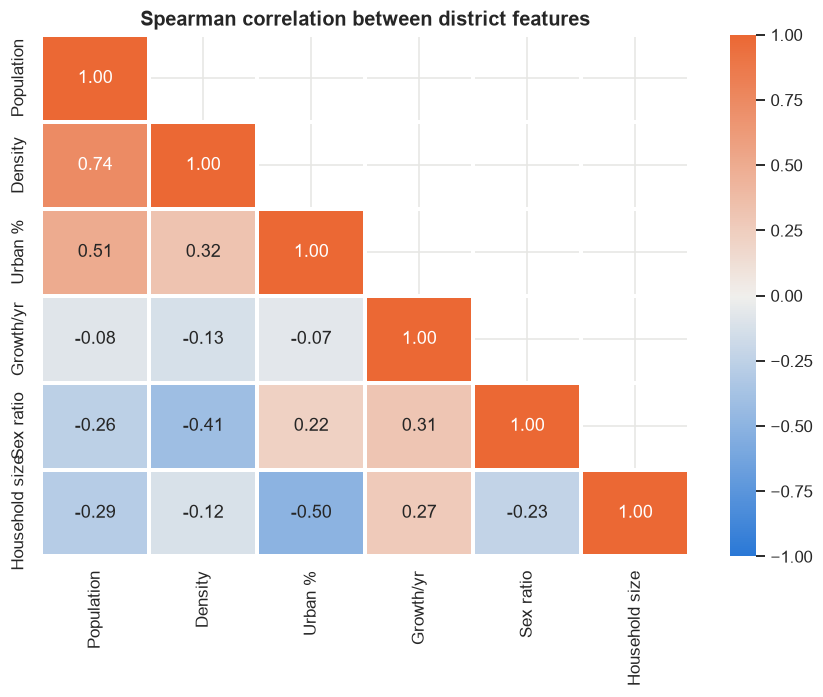

In [25]:
cols = {"POP_2017": "Population", "DENSITY": "Density", "URBAN_%": "Urban %", "CAGR": "Growth/yr",
        "SEX_RATIO": "Sex ratio", "HH_SIZE": "Household size"}
corr = dist[list(cols)].rename(columns=cols).corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, linewidths=1.5, linecolor="white",
            cmap=sns.blend_palette(["#2a78d6", "#f0efec", "#eb6834"], as_cmap=True))
plt.title("Spearman correlation between district features"); plt.tight_layout(); plt.show()

**Interpretation:**

- The heatmap shows rank (Spearman) correlations between six district features. Orange means two features rise together, blue means one rises as the other falls, and a pale colour means almost no relationship. Only the lower half is shown, and the diagonal is always 1.00.
- Population and density have the strongest link (0.74), so large districts also tend to be crowded. Population and urban share are also positively related (0.51), and density and urban share more weakly (0.32).
- The strongest negative value is between urban share and household size (-0.50). The more urban a district, the smaller its households tend to be. Density and sex ratio are also negatively linked (-0.41), which means crowded districts have a more balanced ratio of men to women.
- Urban share and sex ratio have a small positive link (0.22), matching the finding in Plot 14 that cities have more men. Population has weak negative links with household size (-0.29) and sex ratio (-0.26).
- The growth row is mostly near zero. Growth against urban share is -0.07, against population -0.08 and against density -0.13, so growth does not depend on how big, crowded or urban a district is. This confirms Plot 13.
- Growth has weak positive links with sex ratio (0.31) and household size (0.27). Fast-growing districts tend to have more men and larger families. This probably reflects the regional pattern, since these traits are common in Balochistan and KPK, so it should not be read as one factor causing the other.
- Values between -0.3 and 0.3 are weak, and only a few pairs go beyond 0.4 in either direction.
- Spearman correlation was used instead of Pearson because population data is heavily skewed. A few giants such as Lahore and Karachi could distort a Pearson result, while Spearman works on ranks and is not affected in the same way.
- Correlation shows that two things move together, not that one causes the other.

## 8. Key Findings

### Population Size and Growth

- Pakistan's population (without Islamabad) rose from 130.7 million in 1998 to 204.4 million in 2017, an increase of 73.7 million or 56%.
- Yearly growth was 2.38%, which would double the population in about 30 years.
- Punjab is the largest province with 109.1 million people (53%), followed by Sindh with 47.8 million (23%), KPK with 30.5 million (15%), Balochistan with 12.3 million (6%) and KPK/FATA with 4.7 million (2%).
- Balochistan grew fastest at 3.37% a year (+88%), then KPK at 2.88% (+72%). Punjab grew slowest at 2.13% a year (+49%).
- Even so, Punjab added the most people (36.0 million, nearly half of the national increase), and its share of the national population fell from 55.8% to 53.4%.

### Urban and Rural Population

- The urban share rose from 32.4% to 36.4%, so about two out of three Pakistanis still live in rural areas.
- Urban population grew at 3.0% a year compared with 2.05% for rural areas, rising from 42.3 million to 74.4 million.
- Sindh is the only province with an urban majority (52%). The others are Punjab 37%, Balochistan 28%, KPK 18% and FATA 3%.
- Punjab urbanised the most, with its urban share up by 5.6 points. FATA barely changed.
- Cities grew faster than villages in every province, and the gap was widest in Punjab (3.0% against 1.7%).

### Largest, Densest and Fastest-Growing Districts

- Lahore is the largest district with 11.1 million people, followed by Faisalabad (7.9 million) and Rawalpindi (5.4 million). Thirteen of the fifteen largest districts are in Punjab. Karachi's six districts combined have 16.0 million people.
- Karachi Central is the most crowded district at about 39,600 people per sq. km. Korangi, Karachi East and Karachi South follow, and Lahore is fifth at 6,275.
- Quetta is the fastest-growing district at 5.8% a year, having almost tripled in size. Seven of the ten fastest-growing districts are in Balochistan.
- The slowest-growing districts are Torghar (-0.1%), Awaran (0.2%) and Orakzai (0.6%). Karachi's older central districts also grew slowly.
- Balochistan is the largest province by area but the emptiest, with only 36 people per sq. km compared with 538 in Punjab.

### Gender and Households

- There are 104.8 men for every 100 women. The ratio is above 100 in every province, in both rural and urban areas.
- Urban areas have more men than rural areas (107.1 against 103.5 nationally), and Balochistan has the highest ratio (111.8 urban).
- The average household has 6.4 people. Households are largest in KPK/FATA (8.64 rural) and KPK (7.91 rural) and smallest in Sindh (5.47 rural).
- The census counted 21,358 transgender persons, and about 55% of them live in urban areas. Sindh has the highest rate (12.4 per 100,000), followed by Punjab (11.3).

### Concentration of Population

- Twenty-six of the 131 districts hold about half of all people. The top 10 hold 27%, the top 60 hold about 80%, and the smallest 65 together hold only about 16%.
- At tehsil level the median tehsil has 260,084 people, but Punjab's median (about 613,000) is roughly 12 times Balochistan's (about 49,000).
- Urban share and growth are not related at district level (correlation -0.07), and growth follows the region more than the type of district.

## 9. Recommendations

- Plan first for the fastest-growing cities. Quetta, Peshawar and the outer parts of Karachi (Malir and Karachi East) need housing, water supply and public transport soonest.
- Balochistan and KPK combine high growth with large households. Investment in schools, health services and family planning should be directed there.
- Karachi's central districts, with up to about 40,000 people per sq. km, need urgent investment in public transport, water and sanitation.
- Rural Pakistan should not be forgotten. About 64% of people live in villages, and creating jobs and services there can reduce the pressure on the cities. Villages in Punjab are growing slowly because people are leaving, so rural development matters most there.

## 10. Limitations and Next Steps

- Islamabad is missing from the file, and the area of four Killa Saifullah tehsils is unknown. The missing area makes Balochistan's density very slightly higher than the true value.
- Only two census years are available, so natural growth, migration and the reclassification of villages as towns cannot be separated.
- District boundaries, especially Karachi's split into six districts, affect rankings and concentration results.
- Next steps are to add the 2023 census for a third time point, draw a district-level map and join the data with literacy or income figures to explain why some areas grow faster than others.